# TP N°3 — Vision par ordinateur

**Module**:Thechnologie D'IA

**Filiere**:ILIA2

**Réalisée par**:Soumia Dahbi N:9

> **Environnement conseillé :** Google Colab pour les exercices Detectron2 et Dlib/face_recognition.  
> **Important :** importer les images demandées (`image.jpg`, `image_objects.jpg`, `people.jpg`, `ref.jpg`, `test.jpg`) lorsqu'une cellule le demande. Les résultats dépendent des images utilisées.

## 0. Installation et importation

Exécuter cette cellule dans Google Colab. Pour OpenCV, NumPy et Matplotlib, l'installation est généralement déjà disponible.

In [1]:
!pip -q install opencv-python-headless numpy matplotlib
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
print("OpenCV :", cv2.__version__)
print("NumPy :", np.__version__)

OpenCV : 5.0.0
NumPy : 2.4.6


# Partie 1 — Concepts de base de la vision par ordinateur

## Exercice 1 : Analyse d'une image

Importer une image, l'afficher, la convertir en niveaux de gris puis détecter ses contours avec Canny.

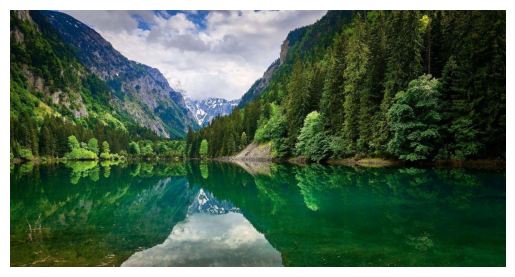

In [3]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("image.jpg")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.axis("off")
plt.show()

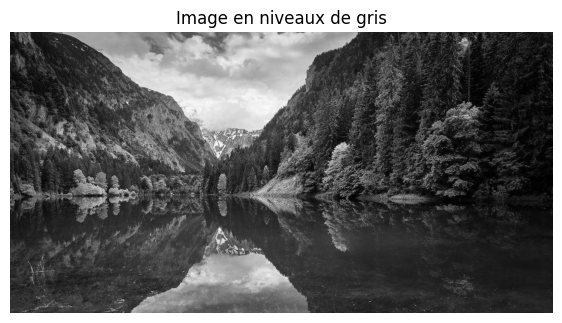

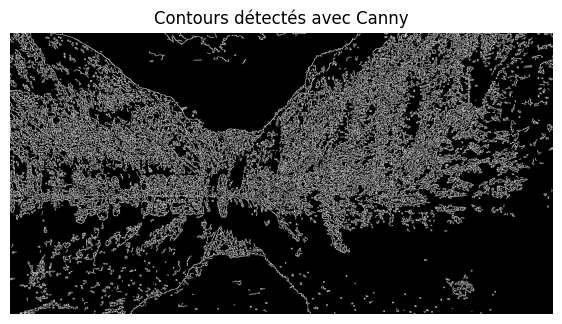

In [4]:
# Conversion en niveaux de gris
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(7, 5))
plt.imshow(gray, cmap="gray")
plt.title("Image en niveaux de gris")
plt.axis("off")
plt.show()

# Détection des contours avec Canny
edges = cv2.Canny(gray, 100, 200)

plt.figure(figsize=(7, 5))
plt.imshow(edges, cmap="gray")
plt.title("Contours détectés avec Canny")
plt.axis("off")
plt.show()

### Questions — Exercice 1

**1. Que représente la matrice retournée par OpenCV pour l'image ?**

Une image est représentée par une matrice NumPy. Chaque élément correspond à un pixel. Pour une image couleur, la matrice possède généralement trois dimensions : hauteur, largeur et 3 canaux (Bleu, Vert, Rouge dans OpenCV). Pour une image en niveaux de gris, elle possède deux dimensions et chaque pixel contient une seule intensité, généralement comprise entre 0 et 255.

**2. Pourquoi convertit-on souvent l'image en niveaux de gris avant traitement ?**

La conversion réduit les informations à traiter : au lieu de manipuler trois canaux de couleur, on travaille avec un seul canal d'intensité. Cela simplifie et accélère plusieurs traitements, comme la détection des contours. Elle est utile lorsque la couleur n'est pas nécessaire à la tâche.

**3. Que peut apporter le filtre gaussien ?**

Le flou gaussien réduit le bruit et les petits détails indésirables de l'image. Il lisse les variations d'intensité et peut rendre la détection des contours plus stable. Exemple : `cv2.GaussianBlur(gray, (5, 5), 0)`. Le noyau `(5, 5)` définit la taille du voisinage utilisé pour le lissage.

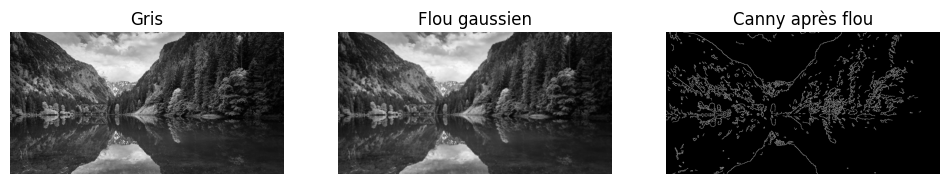

In [5]:
# Exemple : appliquer un flou gaussien avant Canny
blur = cv2.GaussianBlur(gray, (5, 5), 0)
edges_blur = cv2.Canny(blur, 100, 200)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(gray, cmap="gray"); plt.title("Gris"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(blur, cmap="gray"); plt.title("Flou gaussien"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(edges_blur, cmap="gray"); plt.title("Canny après flou"); plt.axis("off")
plt.show()

# Partie 2 — Traitement d'images et vidéos avec OpenCV

## Exercice 2 : Lecture vidéo / webcam

Le code suivant fonctionne sur un ordinateur local avec une webcam. Dans Colab, l'accès direct à `cv2.VideoCapture(0)` n'est généralement pas disponible : on peut plutôt importer une vidéo enregistrée et la traiter.

### Variante Colab : traiter une vidéo enregistrée

Importer une vidéo (par exemple `video.mp4`). Le programme convertit chaque image de la vidéo en niveaux de gris et enregistre le résultat dans `video_gris.mp4`.

### Question — Exercice 2

**Que se passe-t-il si vous utilisez une vidéo enregistrée à la place de la webcam ?**

Au lieu de recevoir les images en direct depuis la caméra, OpenCV lit successivement les images du fichier vidéo. Le traitement (conversion en niveaux de gris) reste le même. La vidéo se termine lorsque toutes les images ont été lues. Avec une webcam, le flux continue jusqu'à l'appui sur `q` ou l'arrêt de la caméra.

In [9]:
# Lecture d'une vidéo ou webcam
cap = cv2.VideoCapture(0)  # 0 pour la webcam, ou remplacer par le chemin d'une vidéo

while True:
    ret, frame = cap.read()
    if not ret:
        break
    cv2.imshow('Webcam', frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

import cv2

cap = cv2.VideoCapture(1)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter('video.mp4.mp4', fourcc, 20.0, (w, h), isColor=False)

while True:
    ret, frame = cap.read()
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    out.write(gray)
    cv2.imshow('Enregistrement', gray)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
out.release()
cv2.destroyAllWindows()

# Partie 3 — Détection et segmentation d'objets avec Detectron2

## Exercice 3 : Détection d'objets avec Mask R-CNN

**À exécuter de préférence dans Google Colab.** L'installation de Detectron2 peut dépendre des versions de PyTorch et de l'environnement Colab.

In [ ]:
# Installation Detectron2 dans Colab
!pip -q install 'git+https://github.com/facebookresearch/detectron2.git'

In [ ]:
import cv2
import torch
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog
from google.colab import files
from google.colab.patches import cv2_imshow

uploaded = files.upload()  # Importer image_objects.jpg
objects_path = "image_objects.jpg"

img_objects = cv2.imread(objects_path)
if img_objects is None:
    raise FileNotFoundError("Importer une image nommée image_objects.jpg.")

CONFIG = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CONFIG))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG)
cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

predictor = DefaultPredictor(cfg)
outputs = predictor(img_objects)

visualizer = Visualizer(
    img_objects[:, :, ::-1],
    MetadataCatalog.get(cfg.DATASETS.TRAIN[0]),
    scale=1.2
)
result_image = visualizer.draw_instance_predictions(outputs["instances"].to("cpu"))
cv2_imshow(result_image.get_image()[:, :, ::-1])

instances = outputs["instances"].to("cpu")
print("Nombre d'objets détectés :", len(instances))

### Questions — Exercice 3

**1. Quels objets ont été détectés ?**

La liste dépend de l'image fournie. Le modèle pré-entraîné COCO peut reconnaître notamment des personnes, voitures, vélos, chiens, chats, chaises et plusieurs autres catégories. Lire les étiquettes affichées sur le résultat pour donner les objets réellement détectés dans votre image.

**2. Modifiez le seuil `SCORE_THRESH_TEST` et observez l'effet sur la détection.**

Le seuil représente le niveau minimal de confiance demandé pour conserver une détection. Un seuil plus élevé (par exemple 0.8) conserve seulement les prédictions les plus confiantes : il peut réduire les faux positifs, mais aussi éliminer des objets réellement présents. Un seuil plus faible (par exemple 0.2) affiche davantage de détections, mais augmente le risque de fausses détections.

  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-w2if0z7y
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-w2if0z7y
  Resolved https://github.com/facebookresearch/detectron2.git to commit 247691a1c292654867deb35cabb27f18d75a1363
  Preparing metadata (pyproject.toml) ... done


model_final_f10217.pkl: 178MB [00:03, 52.7MB/s]                           
/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1113 23:08:54.258000 9230 torch/fx/_symbolic_trace.py:57] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


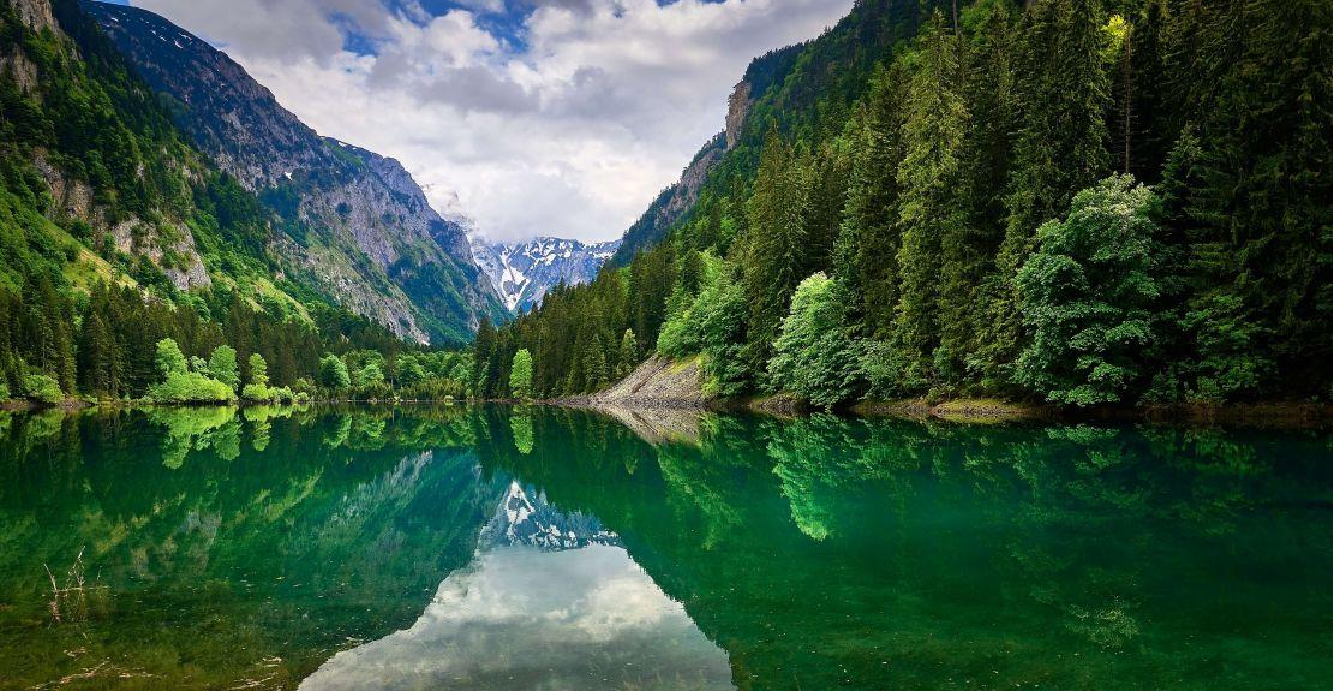

In [15]:
# Installation de Detectron2
!pip install --no-build-isolation 'git+https://github.com/facebookresearch/detectron2.git'

import cv2
import torch
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog
from google.colab.patches import cv2_imshow

# Configuration du modèle Mask R-CNN
CONFIG = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CONFIG))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG)

# FORCER L'UTILISATION DU CPU (pour éviter l'erreur CUDA)
cfg.MODEL.DEVICE = "cpu"

predictor = DefaultPredictor(cfg)

# Charger l'image (assurez-vous que l'image "image.jpg" est bien présente)
img = cv2.imread("image.jpg")

# Prédiction
outputs = predictor(img)

# Visualisation
v = Visualizer(img[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

# Affichage sous Colab
cv2_imshow(out.get_image()[:, :, ::-1])

# Partie 4 — Détection et reconnaissance faciale avec Dlib

## Exercice 4 : Détection faciale

Importer une image contenant un ou plusieurs visages et la nommer `people.jpg`.

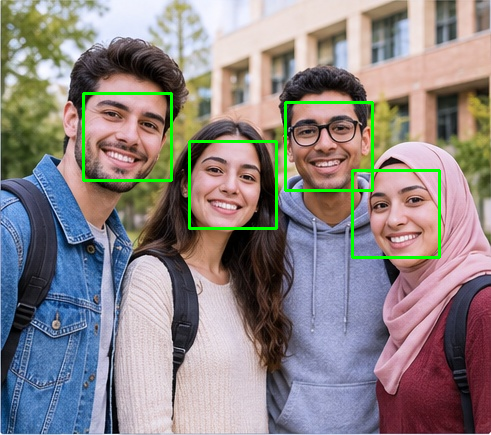

In [16]:
import dlib
import cv2
from google.colab.patches import cv2_imshow

detector = dlib.get_frontal_face_detector()
img = cv2.imread("people.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

faces = detector(gray)

for face in faces:
    x, y, w, h = face.left(), face.top(), face.width(), face.height()
    cv2.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 2)

cv2_imshow(img)

## Exercice 5 : Reconnaissance faciale

Comparer une image de référence `ref.jpg` et une image test `test.jpg`. `face_recognition` transforme chaque visage en un encodage numérique, puis compare les encodages.

### Questions — Exercice 5






**1. Que se passe-t-il si l'image test contient plusieurs visages ?**

`face_recognition.face_encodings(image_test)` retourne une liste d'encodages, un par visage détecté. Dans le code précédent, `encodings_test[0]` compare uniquement le premier visage trouvé avec le visage de référence. Pour comparer tous les visages, il faut parcourir la liste et comparer chaque encodage à celui de référence.

**2. Quelle précision attendre dans des conditions réelles (lumière, angles différents) ?**

La précision peut diminuer lorsque l'éclairage est faible ou très différent, lorsque le visage est tourné, partiellement caché, flou ou éloigné. Le résultat dépend aussi de la qualité des images et du seuil de comparaison. Il ne faut donc pas considérer une reconnaissance comme infaillible ; une application réelle doit prévoir des vérifications et tenir compte des erreurs possibles.

In [19]:
# Installation des bibliothèques si elles ne le sont pas
!pip install dlib face_recognition

import face_recognition
import os

# Désactiver CUDA pour dlib
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# Charger les images (assurez-vous que ref.jpg et test.jpg existent)
image_ref = face_recognition.load_image_file("ref.jpg")
encodage_ref = face_recognition.face_encodings(image_ref)[0]

image_test = face_recognition.load_image_file("test.jpg")
encodage_test = face_recognition.face_encodings(image_test)[0]

# Comparer les visages
result = face_recognition.compare_faces([encodage_ref], encodage_test)
print("Même personne ?", result[0])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 24.8 MB/s  0:00:04
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for face-recognition-models: filename=face_recognition_models-0.3.0-py2.py3-none-any.whl size=100566240 sha256=37f588fd9271e61378dbf5d44001b477d53885e87a1e4e62ecfb5b9146dd8041
  Stored in directory: /root/.cache/pip/wheels/39/20/47/6b647a3457f0e36c161b2516a5bd7f29f6bbd5e3a67c46a710
Successfully built face-recognition-models
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [face_recognition]
Même personne ? True


# Partie 5 — Exercices complémentaires

## Exercice 6 : Points caractéristiques du visage (landmarks)

Les landmarks localisent des points caractéristiques, par exemple le contour du menton, les sourcils, les yeux, le nez et la bouche.

Visages détectés: 4


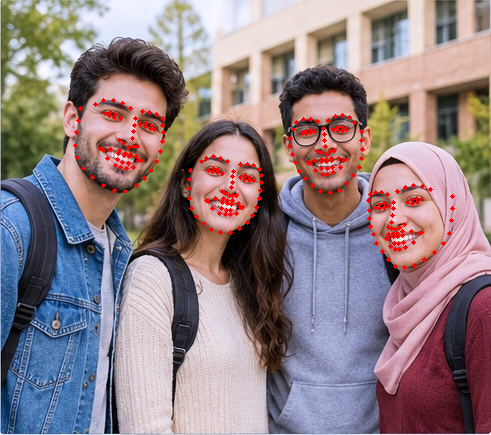

In [21]:
import cv2
import face_recognition
from google.colab.patches import cv2_imshow

img = cv2.imread("people.jpg")
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # face_recognition attend du RGB

landmarks_list = face_recognition.face_landmarks(rgb)
print("Visages détectés:", len(landmarks_list))

for landmarks in landmarks_list:
    for partie, points in landmarks.items():
        for (x, y) in points:
            cv2.circle(img, (x, y), 2, (0, 0, 255), -1)

cv2_imshow(img)

### Questions — Exercice 6

**1. Quelles parties du visage sont retournées par `face_landmarks` ?**

La fonction retourne notamment les régions `chin` (menton/contour du visage), `left_eyebrow` et `right_eyebrow` (sourcils), `left_eye` et `right_eye` (yeux), `nose_bridge` et `nose_tip` (nez), `top_lip` et `bottom_lip` (lèvres).

**2. Comment calculer le rapport d'ouverture de l'œil (EAR) et l'utiliser ?**

Pour six points autour d'un œil, le rapport EAR est :

\[
EAR = \frac{\|p_2-p_6\| + \|p_3-p_5\|}{2\|p_1-p_4\|}
\]

Les distances verticales diminuent lorsque l'œil se ferme, tandis que la distance horizontale varie moins. On peut donc surveiller l'EAR au fil des images : s'il reste inférieur à un seuil pendant une durée déterminée, le système peut signaler une fermeture prolongée de l'œil. Le seuil doit être adapté à la personne et aux conditions de capture.

## Exercice 7 : Détection d'objets en temps réel avec YOLO

YOLOv8n est un modèle léger de détection. Le modèle `yolov8n-seg.pt` ajoute la segmentation d'instances.

In [ ]:
!pip -q install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 10.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

image 1/1 /content/image_objects.jpg: 448x640 1 person, 1 bicycle, 1 car, 1 dog, 233.9ms
Speed: 8.3ms preprocess, 233.9ms inference, 4.3ms postprocess per image at shape (1, 3, 448, 640)


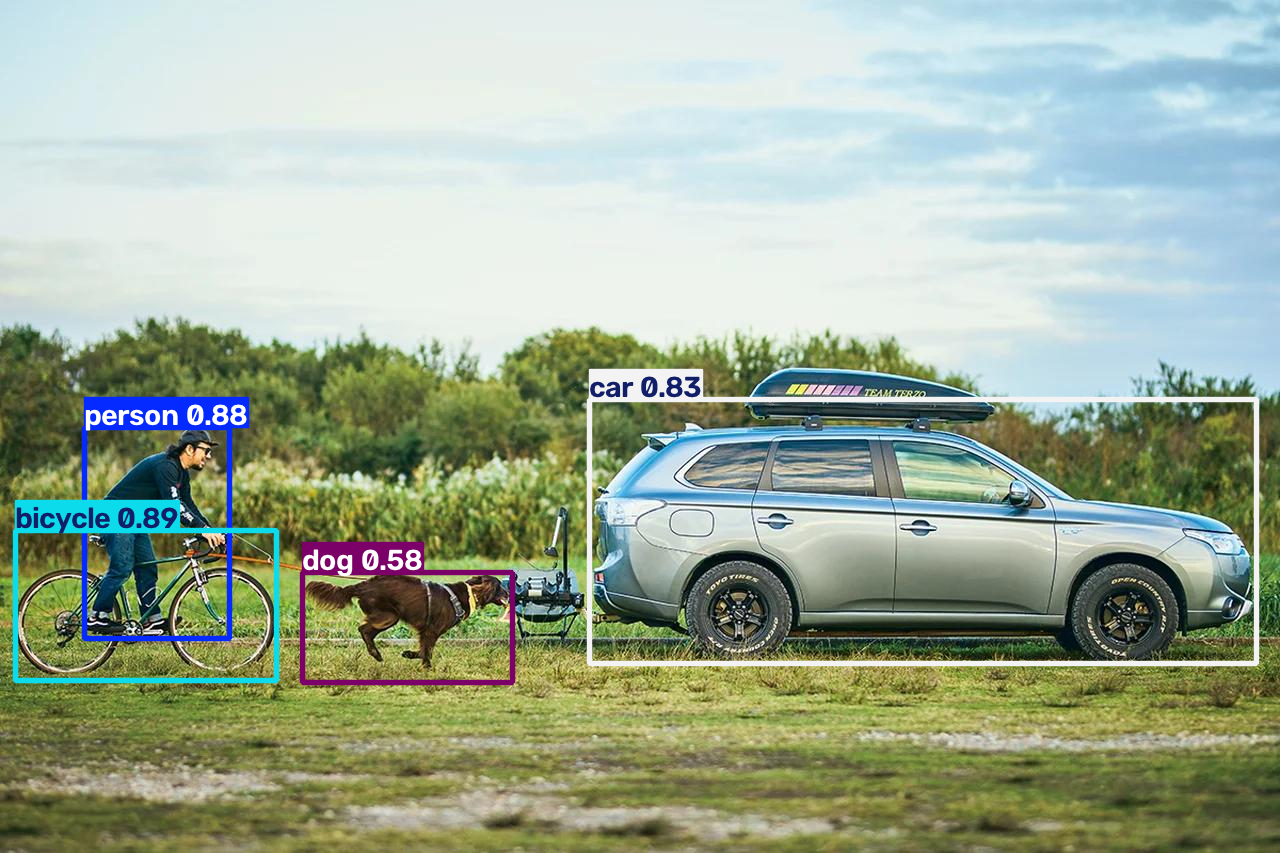

In [23]:
!pip install ultralytics
import os
from ultralytics import YOLO
import cv2
from google.colab.patches import cv2_imshow

model = YOLO("yolov8n.pt")  # Téléchargement automatique du modèle léger

image_path = "image_objects.jpg"
if not os.path.exists(image_path):
    print(f"'{image_path}' non trouvé. Utilisation de 'people.jpg' à la place.")
    image_path = "people.jpg"

try:
    results = model(image_path, conf=0.5)
    cv2_imshow(results[0].plot())
except Exception as e:
    print("Erreur lors de la détection:", e)

### Questions — Exercice 7

**1. Comparer le temps d'inférence de YOLOv8n et de Mask R-CNN sur la même image.**

Pour une comparaison correcte, utiliser la même image, le même matériel et mesurer uniquement le temps de prédiction (après le chargement des modèles). Les temps varient selon le CPU/GPU et la taille de l'image. YOLOv8n est conçu pour être rapide ; Mask R-CNN réalise aussi une segmentation d'instances et est généralement plus lourd. La cellule ci-dessous mesure les deux modèles si Detectron2 a été installé.

**2. YOLO fournit-il des masques de segmentation ? Testez `yolov8n-seg.pt`.**

Le modèle de détection `yolov8n.pt` fournit des boîtes englobantes et des classes, pas des masques d'instance. Le modèle `yolov8n-seg.pt` est une variante de segmentation et fournit des masques.

**3. Dans quels cas préférer chaque modèle ?**

- **YOLO :** lorsque la vitesse est importante, notamment pour la vidéo et les applications en temps réel.
- **Mask R-CNN :** lorsque l'on souhaite des masques de segmentation d'instances et une analyse plus détaillée des contours des objets, et que le coût de calcul supplémentaire est acceptable.
- **YOLO-seg :** lorsque l'on souhaite également des masques, tout en privilégiant une approche rapide.

# Mini-projet — Floutage automatique des visages


In [30]:
import face_recognition
import cv2
import numpy as np
import os
import csv
from datetime import datetime

# 1. Charger les images et encodages directement depuis le dossier courant
known_face_encodings = []
known_face_names = []

# Liste des fichiers à ignorer (par exemple le script lui-même ou les fichiers générés)
fichiers_a_ignorer = ["presence.csv", "script.py"]

for filename in os.listdir("."):
    if filename.lower().endswith((".jpg", ".png", ".jpeg", ".avif")) and filename not in fichiers_a_ignorer:
        image_path = filename
        image = face_recognition.load_image_file(image_path)
        encodings = face_recognition.face_encodings(image)
        if len(encodings) > 0:
            known_face_encodings.append(encodings[0])
            # Le nom est le nom du fichier sans l'extension
            name = os.path.splitext(filename)[0].capitalize()
            known_face_names.append(name)

print(f"Étudiants enregistrés : {known_face_names}")

# 2. Initialiser le fichier CSV
csv_file = "presence.csv"
if not os.path.exists(csv_file):
    with open(csv_file, mode='w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(["Nom", "Date", "Heure"])

etudiants_presents = set()
cap = cv2.VideoCapture(0)
print("[INFO] Système de présence actif. Appuyez sur 'q' pour quitter.")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    small_frame = cv2.resize(frame, (0, 0), fx=0.5, fy=0.5)
    rgb_small_frame = cv2.cvtColor(small_frame, cv2.COLOR_BGR2RGB)

    face_locations = face_recognition.face_locations(rgb_small_frame)
    face_encodings = face_recognition.face_encodings(rgb_small_frame, face_locations)

    for face_encoding, face_location in zip(face_encodings, face_locations):
        matches = face_recognition.compare_faces(known_face_encodings, face_encoding)
        name = "Inconnu"

        face_distances = face_recognition.face_distance(known_face_encodings, face_encoding)
        if len(face_distances) > 0:
            best_match_index = np.argmin(face_distances)
            if matches[best_match_index]:
                name = known_face_names[best_match_index]
                if name not in etudiants_presents:
                    etudiants_presents.add(name)
                    now = datetime.now()
                    with open(csv_file, mode='a', newline='', encoding='utf-8') as f:
                        writer = csv.writer(f)
                        writer.writerow([name, now.strftime("%Y-%m-%d"), now.strftime("%H:%M:%S")])
                    print(f"[PRÉSENCE] {name} enregistré à {now.strftime('%H:%M:%S')}")

        top, right, bottom, left = [v * 2 for v in face_location]
        color = (0, 255, 0) if name != "Inconnu" else (0, 0, 255)
        cv2.rectangle(frame, (left, top), (right, bottom), color, 2)
        cv2.putText(frame, name, (left, top - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, 2)

    cv2.imshow("Systeme de Presence", frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

Étudiants enregistrés : ['Ref', 'People', 'Mohamed', 'Sara', 'Test', 'Ahmed', 'Face']
[INFO] Système de présence actif. Appuyez sur 'q' pour quitter.
